In [1]:
import os
import pandas as pd

CSV_YOLU = "data/breast_cancer.csv"
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
TEMEL = ["yaricap", "doku", "cevre", "alan", "puruzsuzluk", "yogunluk", "iclik", "ic_nokta", "simetri", "fraktal"]
SUTUNLAR = ["id", "tani"] + [f"{t}_{s}" for s in ["ort", "se", "en_kotu"] for t in TEMEL]

if not os.path.exists(CSV_YOLU):
    os.makedirs("data", exist_ok=True)
    pd.read_csv(URL, header=None, names=SUTUNLAR).to_csv(CSV_YOLU, index=False)
    print("Veri seti indirildi ve CSV olarak kaydedildi.")
else:
    print("Veri seti mevcut:", CSV_YOLU)

Veri seti mevcut: data/breast_cancer.csv


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.colors import ListedColormap

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     cross_validate, learning_curve)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             matthews_corrcoef, cohen_kappa_score, balanced_accuracy_score, log_loss)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
%matplotlib inline

df = pd.read_csv(CSV_YOLU)
print("Veri seti başarıyla yüklendi.")
df.head(10)

Veri seti başarıyla yüklendi.


,id,tani,yaricap_ort,doku_ort,cevre_ort,alan_ort,puruzsuzluk_ort,yogunluk_ort,iclik_ort,ic_nokta_ort,simetri_ort,fraktal_ort,yaricap_se,doku_se,cevre_se,alan_se,puruzsuzluk_se,yogunluk_se,iclik_se,ic_nokta_se,simetri_se,fraktal_se,yaricap_en_kotu,doku_en_kotu,cevre_en_kotu,alan_en_kotu,puruzsuzluk_en_kotu,yogunluk_en_kotu,iclik_en_kotu,ic_nokta_en_kotu,simetri_en_kotu,fraktal_en_kotu
0,842302,M,17.9900,10.3800,122.8000,1001.0000,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,1.0950,0.9053,8.5890,153.4000,0.0064,0.0490,0.0537,0.0159,0.0300,0.0062,25.3800,17.3300,184.6000,2019.0000,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
1,842517,M,20.5700,17.7700,132.9000,1326.0000,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,0.5435,0.7339,3.3980,74.0800,0.0052,0.0131,0.0186,0.0134,0.0139,0.0035,24.9900,23.4100,158.8000,1956.0000,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890
2,84300903,M,19.6900,21.2500,130.0000,1203.0000,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,0.7456,0.7869,4.5850,94.0300,0.0062,0.0401,0.0383,0.0206,0.0225,0.0046,23.5700,25.5300,152.5000,1709.0000,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876
3,84348301,M,11.4200,20.3800,77.5800,386.1000,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,0.4956,1.1560,3.4450,27.2300,0.0091,0.0746,0.0566,0.0187,0.0596,0.0092,14.9100,26.5000,98.8700,567.7000,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730
4,84358402,M,20.2900,14.3400,135.1000,1297.0000,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,0.7572,0.7813,5.4380,94.4400,0.0115,0.0246,0.0569,0.0188,0.0176,0.0051,22.5400,16.6700,152.2000,1575.0000,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768
5,843786,M,12.4500,15.7000,82.5700,477.1000,0.1278,0.1700,0.1578,0.0809,0.2087,0.0761,0.3345,0.8902,2.2170,27.1900,0.0075,0.0335,0.0367,0.0114,0.0216,0.0051,15.4700,23.7500,103.4000,741.6000,0.1791,0.5249,0.5355,0.1741,0.3985,0.1244
6,844359,M,18.2500,19.9800,119.6000,1040.0000,0.0946,0.1090,0.1127,0.0740,0.1794,0.0574,0.4467,0.7732,3.1800,53.9100,0.0043,0.0138,0.0225,0.0104,0.0137,0.0022,22.8800,27.6600,153.2000,1606.0000,0.1442,0.2576,0.3784,0.1932,0.3063,0.0837
7,84458202,M,13.7100,20.8300,90.2000,577.9000,0.1189,0.1645,0.0937,0.0599,0.2196,0.0745,0.5835,1.3770,3.8560,50.9600,0.0088,0.0303,0.0249,0.0145,0.0149,0.0054,17.0600,28.1400,110.6000,897.0000,0.1654,0.3682,0.2678,0.1556,0.3196,0.1151
8,844981,M,13.0000,21.8200,87.5000,519.8000,0.1273,0.1932,0.1859,0.0935,0.2350,0.0739,0.3063,1.0020,2.4060,24.3200,0.0057,0.0350,0.0355,0.0123,0.0214,0.0037,15.4900,30.7300,106.2000,739.3000,0.1703,0.5401,0.5390,0.2060,0.4378,0.1072
9,84501001,M,12.4600,24.0400,83.9700,475.9000,0.1186,0.2396,0.2273,0.0854,0.2030,0.0824,0.2976,1.5990,2.0390,23.9400,0.0071,0.0722,0.0774,0.0143,0.0179,0.0101,15.0900,40.6800,97.6500,711.4000,0.1853,1.0580,1.1050,0.2210,0.4366,0.2075


In [3]:
df.tail()

,id,tani,yaricap_ort,doku_ort,cevre_ort,alan_ort,puruzsuzluk_ort,yogunluk_ort,iclik_ort,ic_nokta_ort,simetri_ort,fraktal_ort,yaricap_se,doku_se,cevre_se,alan_se,puruzsuzluk_se,yogunluk_se,iclik_se,ic_nokta_se,simetri_se,fraktal_se,yaricap_en_kotu,doku_en_kotu,cevre_en_kotu,alan_en_kotu,puruzsuzluk_en_kotu,yogunluk_en_kotu,iclik_en_kotu,ic_nokta_en_kotu,simetri_en_kotu,fraktal_en_kotu
564,926424,M,21.5600,22.3900,142.0000,1479.0000,0.1110,0.1159,0.2439,0.1389,0.1726,0.0562,1.1760,1.2560,7.6730,158.7000,0.0103,0.0289,0.0520,0.0245,0.0111,0.0042,25.4500,26.4000,166.1000,2027.0000,0.1410,0.2113,0.4107,0.2216,0.2060,0.0712
565,926682,M,20.1300,28.2500,131.2000,1261.0000,0.0978,0.1034,0.1440,0.0979,0.1752,0.0553,0.7655,2.4630,5.2030,99.0400,0.0058,0.0242,0.0395,0.0168,0.0190,0.0025,23.6900,38.2500,155.0000,1731.0000,0.1166,0.1922,0.3215,0.1628,0.2572,0.0664
566,926954,M,16.6000,28.0800,108.3000,858.1000,0.0846,0.1023,0.0925,0.0530,0.1590,0.0565,0.4564,1.0750,3.4250,48.5500,0.0059,0.0373,0.0473,0.0156,0.0132,0.0039,18.9800,34.1200,126.7000,1124.0000,0.1139,0.3094,0.3403,0.1418,0.2218,0.0782
567,927241,M,20.6000,29.3300,140.1000,1265.0000,0.1178,0.2770,0.3514,0.1520,0.2397,0.0702,0.7260,1.5950,5.7720,86.2200,0.0065,0.0616,0.0712,0.0166,0.0232,0.0062,25.7400,39.4200,184.6000,1821.0000,0.1650,0.8681,0.9387,0.2650,0.4087,0.1240
568,92751,B,7.7600,24.5400,47.9200,181.0000,0.0526,0.0436,0.0000,0.0000,0.1587,0.0588,0.3857,1.4280,2.5480,19.1500,0.0072,0.0047,0.0000,0.0000,0.0268,0.0028,9.4560,30.3700,59.1600,268.6000,0.0900,0.0644,0.0000,0.0000,0.2871,0.0704


In [4]:
OZELLIKLER = [k for k in df.columns if k not in ("id", "tani")]
print(f"Gözlem sayısı           : {df.shape[0]}")
print(f"Değişken sayısı         : {df.shape[1]} (id + hedef + {len(OZELLIKLER)} özellik)")
print(f"Toplam eksik değer      : {df.isna().sum().sum()}")
print(f"Tekrarlanan satır sayısı: {df.duplicated().sum()}")
print(f"Tekrarlanan id sayısı   : {df['id'].duplicated().sum()}")
print()
df.info()

Gözlem sayısı           : 569
Değişken sayısı         : 32 (id + hedef + 30 özellik)
Toplam eksik değer      : 0
Tekrarlanan satır sayısı: 0
Tekrarlanan id sayısı   : 0

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   569 non-null    int64  
 1   tani                 569 non-null    str    
 2   yaricap_ort          569 non-null    float64
 3   doku_ort             569 non-null    float64
 4   cevre_ort            569 non-null    float64
 5   alan_ort             569 non-null    float64
 6   puruzsuzluk_ort      569 non-null    float64
 7   yogunluk_ort         569 non-null    float64
 8   iclik_ort            569 non-null    float64
 9   ic_nokta_ort         569 non-null    float64
 10  simetri_ort          569 non-null    float64
 11  fraktal_ort          569 non-null    float64
 12  yaricap_se           569 non-nu

,Frekans,Oran (%)
tani,,
İyi huylu (B),357,62.7417
Kötü huylu (M),212,37.2583


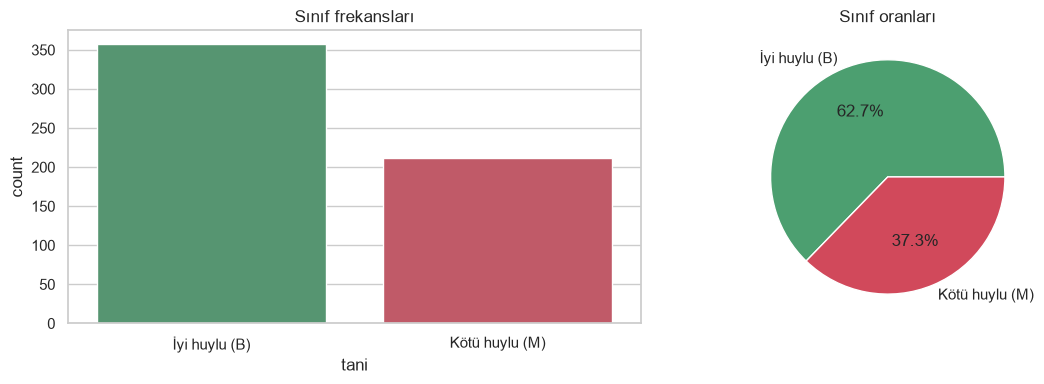

Dengesizlik oranı (B/M): 1.68


In [5]:
SINIF_ADI = {"B": "İyi huylu (B)", "M": "Kötü huylu (M)"}
dagilim = pd.DataFrame({"Frekans": df["tani"].value_counts(),
                        "Oran (%)": df["tani"].value_counts(normalize=True) * 100})
dagilim.index = dagilim.index.map(SINIF_ADI)
display(dagilim)

RENK = {"B": "#4C9F70", "M": "#D1495B"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="tani", hue="tani", palette=RENK, order=["B", "M"], ax=axes[0], legend=False)
axes[0].set_xticks([0, 1], [SINIF_ADI["B"], SINIF_ADI["M"]])
axes[0].set_title("Sınıf frekansları")
axes[1].pie(dagilim["Frekans"], labels=dagilim.index, autopct="%1.1f%%", colors=[RENK["B"], RENK["M"]])
axes[1].set_title("Sınıf oranları")
plt.tight_layout()
plt.show()
print(f"Dengesizlik oranı (B/M): {dagilim['Frekans'].iloc[0] / dagilim['Frekans'].iloc[1]:.2f}")

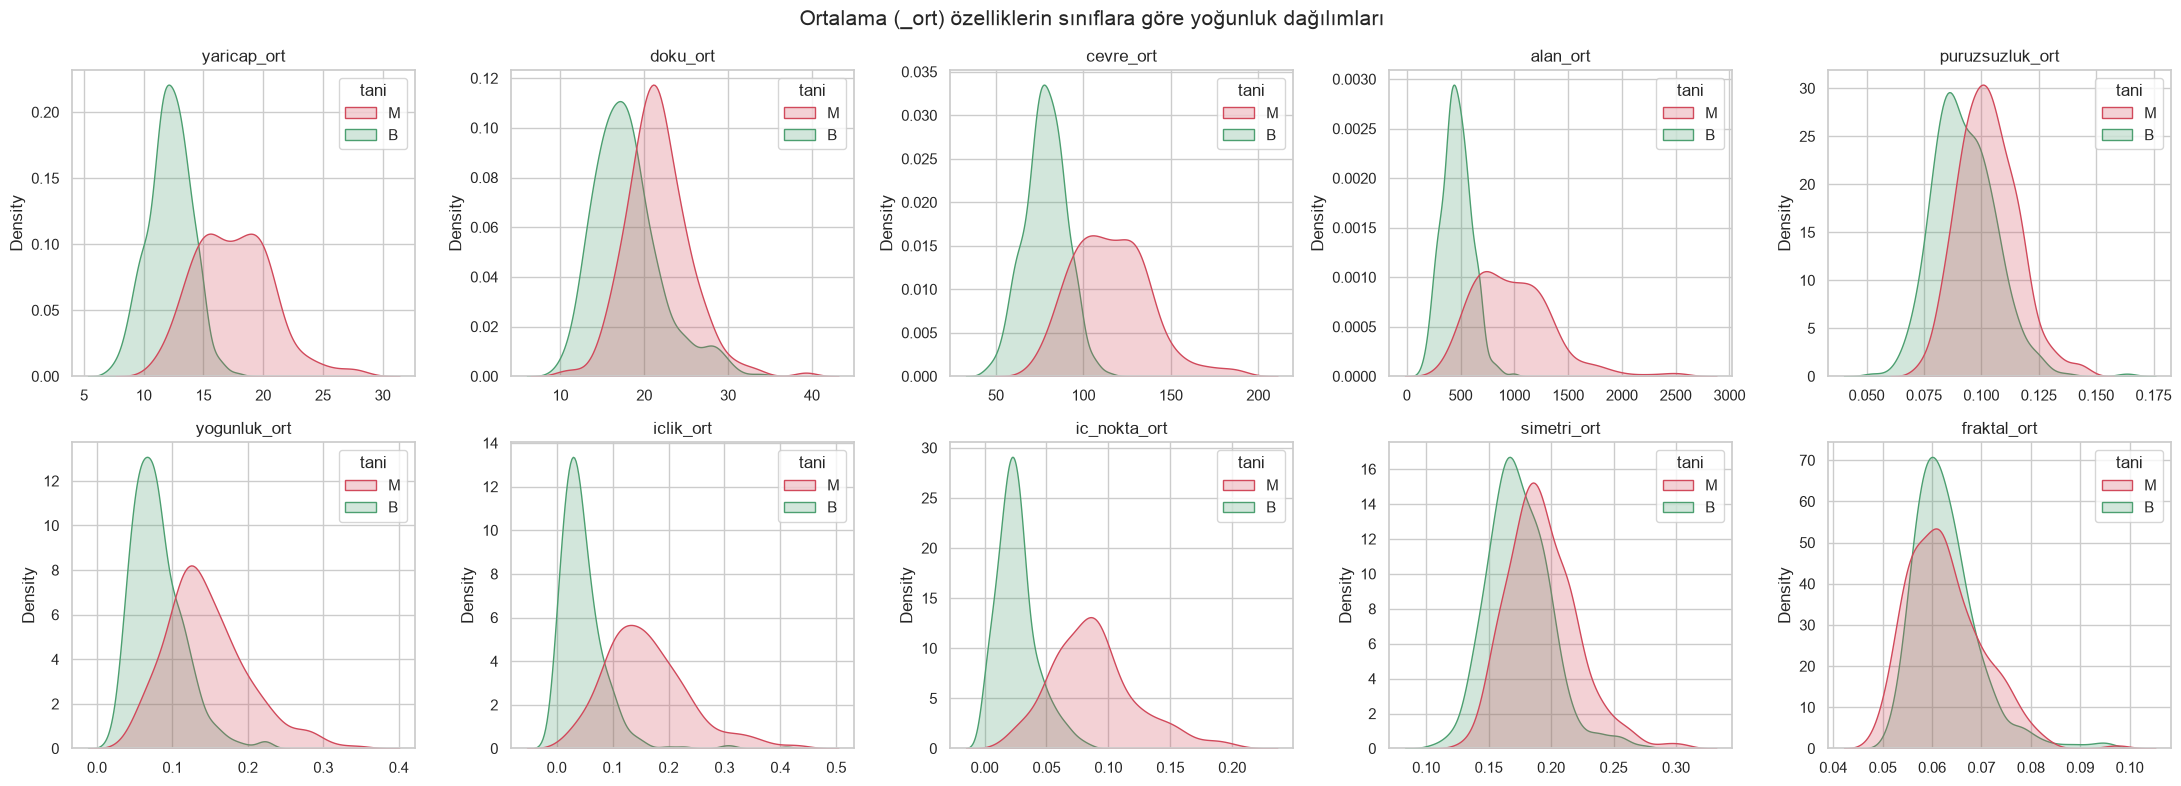

In [6]:
ort_ozellikler = [f"{t}_ort" for t in TEMEL]
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, kol in zip(axes.flat, ort_ozellikler):
    sns.kdeplot(data=df, x=kol, hue="tani", fill=True, common_norm=False, palette=RENK, ax=ax)
    ax.set_title(kol)
    ax.set_xlabel("")
fig.suptitle("Ortalama (_ort) özelliklerin sınıflara göre yoğunluk dağılımları", fontsize=15)
plt.tight_layout()
plt.show()

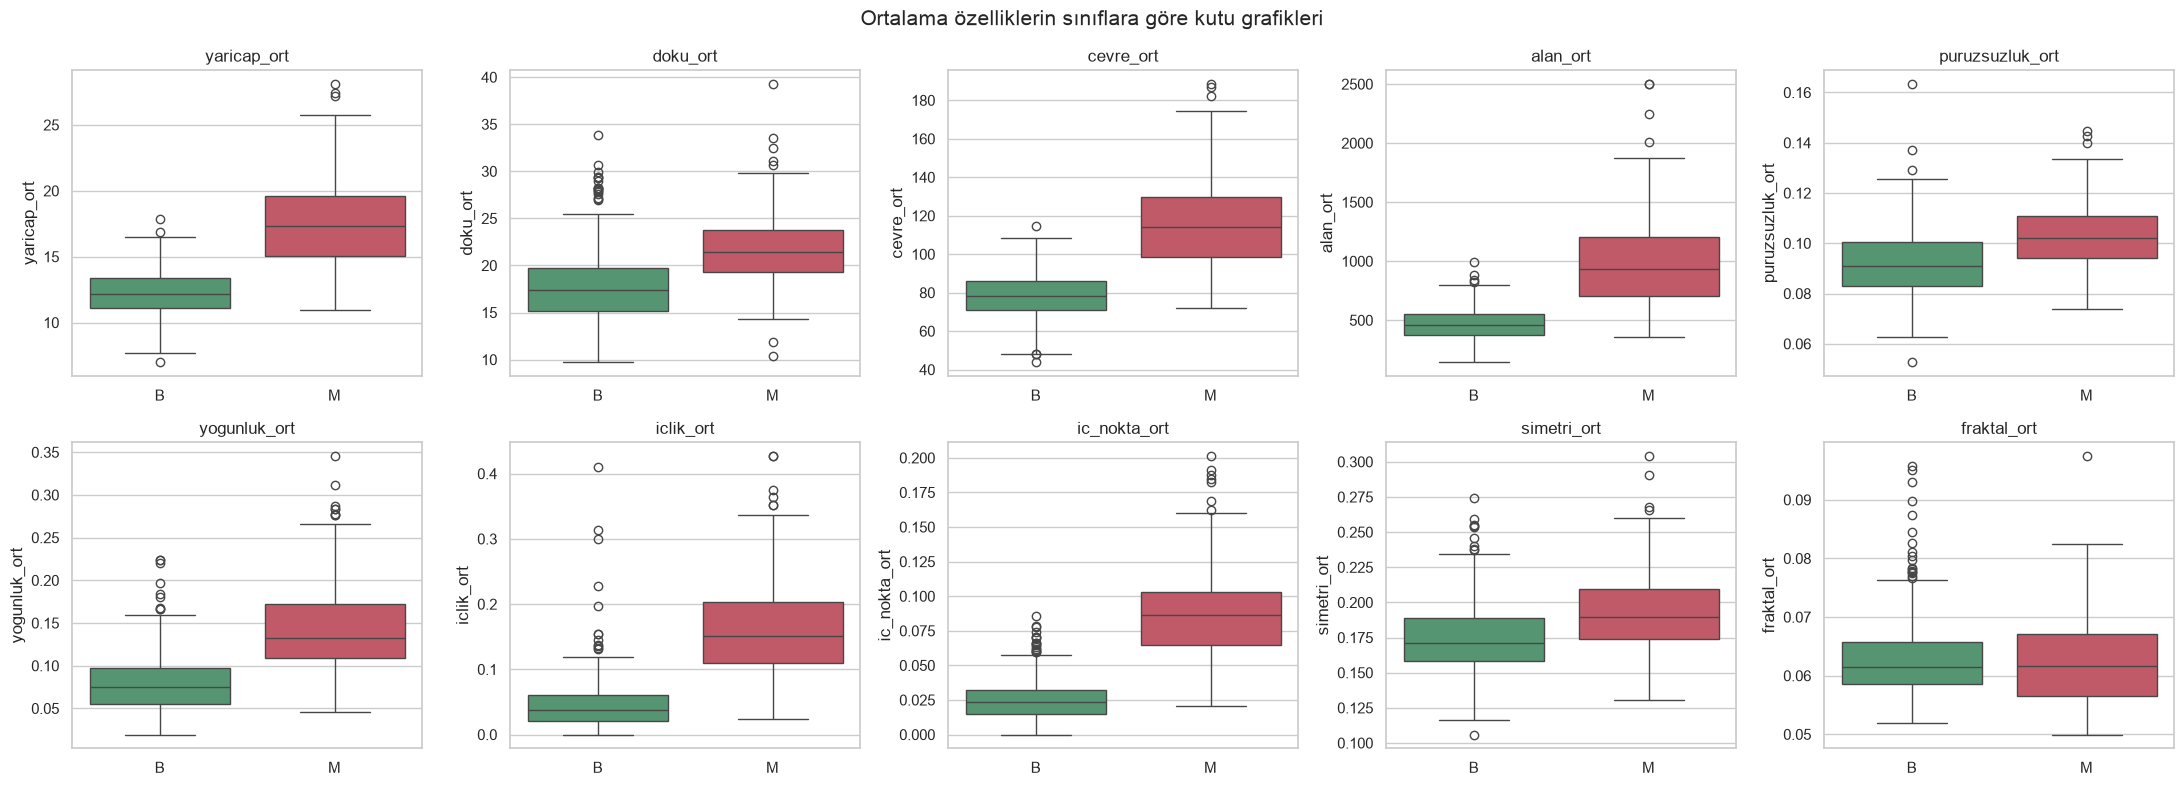

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, kol in zip(axes.flat, ort_ozellikler):
    sns.boxplot(data=df, x="tani", y=kol, hue="tani", palette=RENK, order=["B", "M"], ax=ax, legend=False)
    ax.set_title(kol)
    ax.set_xlabel("")
fig.suptitle("Ortalama özelliklerin sınıflara göre kutu grafikleri", fontsize=15)
plt.tight_layout()
plt.show()

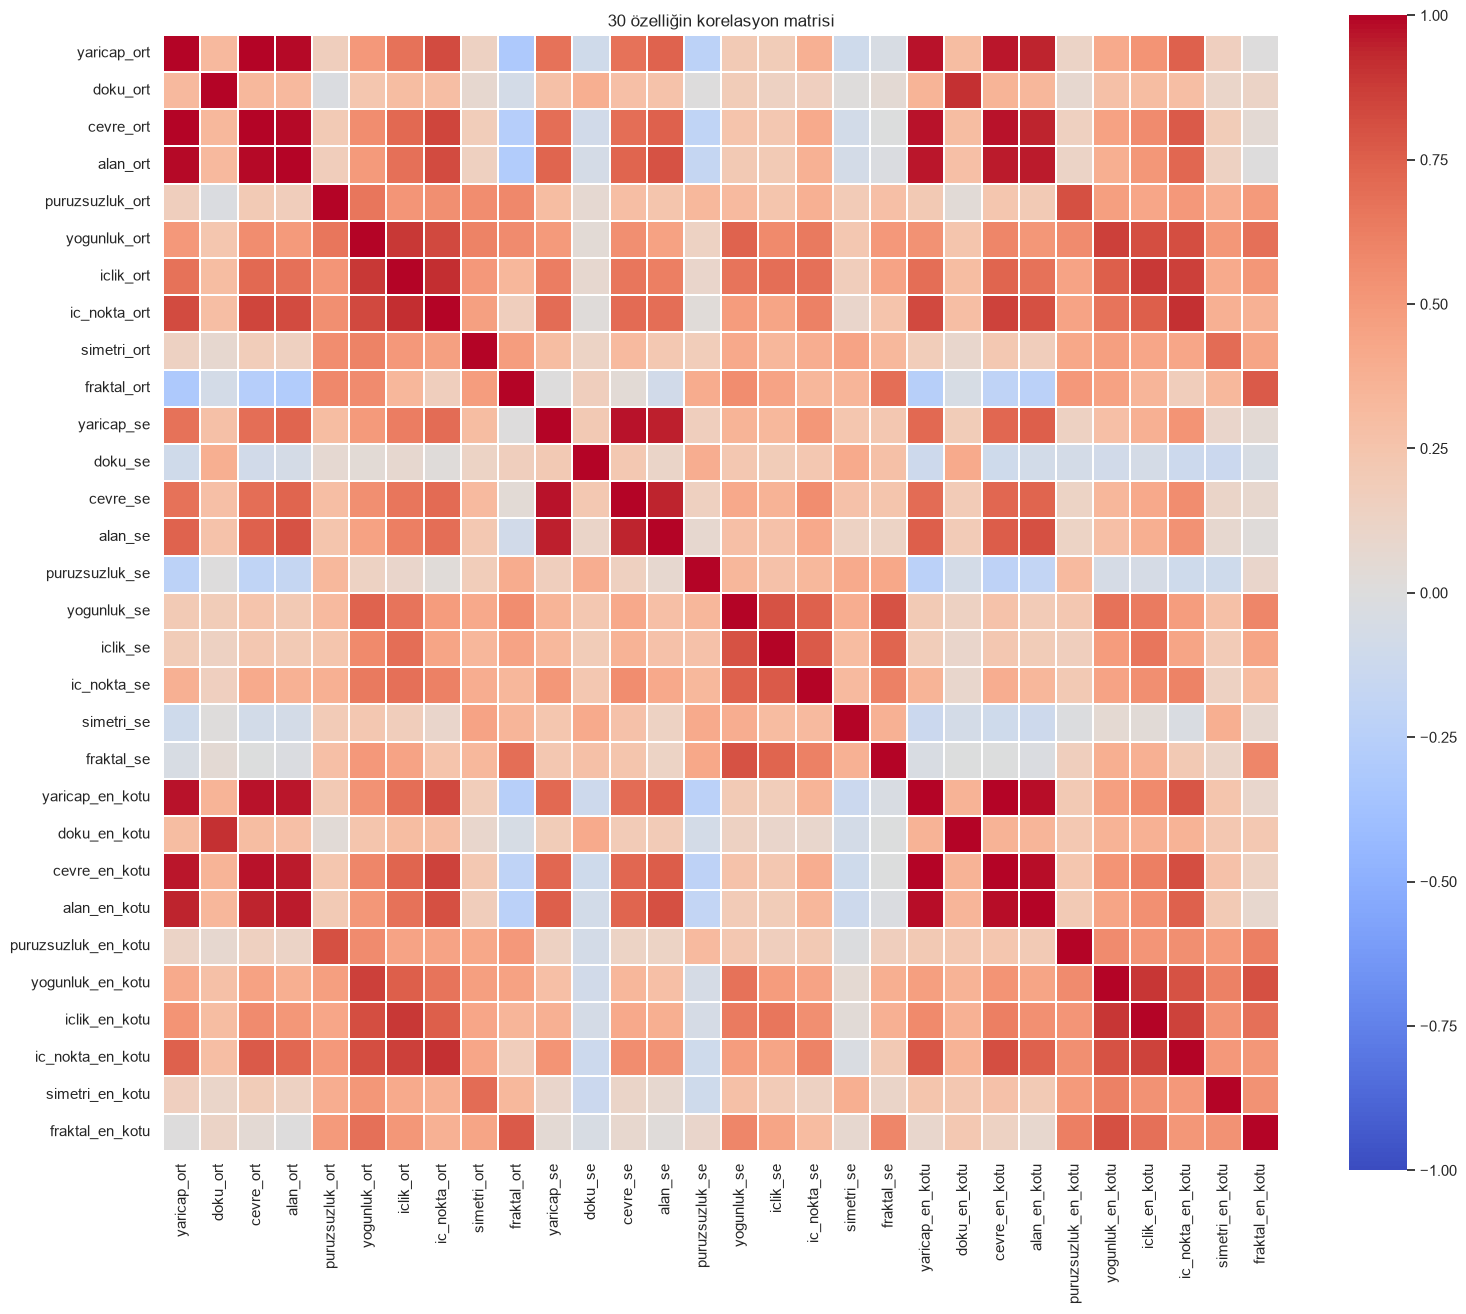

In [8]:
plt.figure(figsize=(18, 15))
sns.heatmap(df[OZELLIKLER].corr(), cmap="coolwarm", vmin=-1, vmax=1, square=True, linewidths=0.2)
plt.title("30 özelliğin korelasyon matrisi")
plt.show()

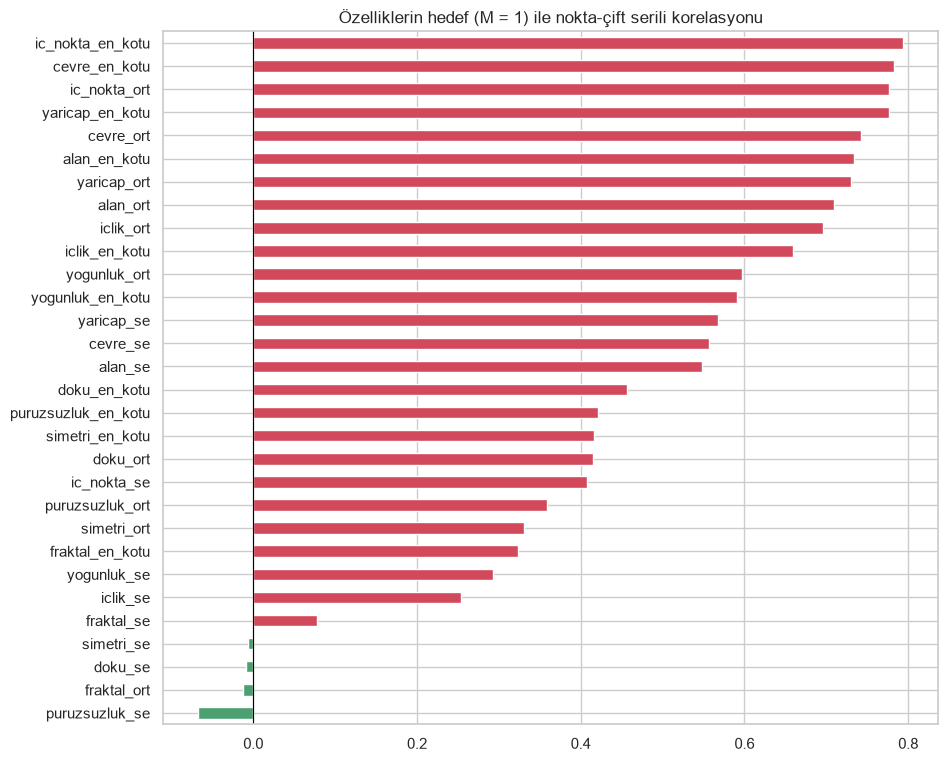

In [9]:
y_sayisal = (df["tani"] == "M").astype(int)
hedef_kor = df[OZELLIKLER].corrwith(y_sayisal).sort_values()
plt.figure(figsize=(10, 9))
hedef_kor.plot.barh(color=np.where(hedef_kor > 0, RENK["M"], RENK["B"]))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Özelliklerin hedef (M = 1) ile nokta-çift serili korelasyonu")
plt.show()

In [10]:
kor = df[OZELLIKLER].corr().where(np.triu(np.ones((len(OZELLIKLER),) * 2, dtype=bool), k=1))
yuksek = kor.stack().loc[lambda s: s.abs() > 0.95].sort_values(ascending=False).to_frame("r")
print(f"|r| > 0.95 olan özellik çifti sayısı: {len(yuksek)}")
yuksek

|r| > 0.95 olan özellik çifti sayısı: 15


,,r
yaricap_ort,cevre_ort,0.9979
yaricap_en_kotu,cevre_en_kotu,0.9937
yaricap_ort,alan_ort,0.9874
cevre_ort,alan_ort,0.9865
yaricap_en_kotu,alan_en_kotu,0.9840
cevre_en_kotu,alan_en_kotu,0.9776
yaricap_se,cevre_se,0.9728
cevre_ort,cevre_en_kotu,0.9704
yaricap_ort,yaricap_en_kotu,0.9695
cevre_ort,yaricap_en_kotu,0.9695


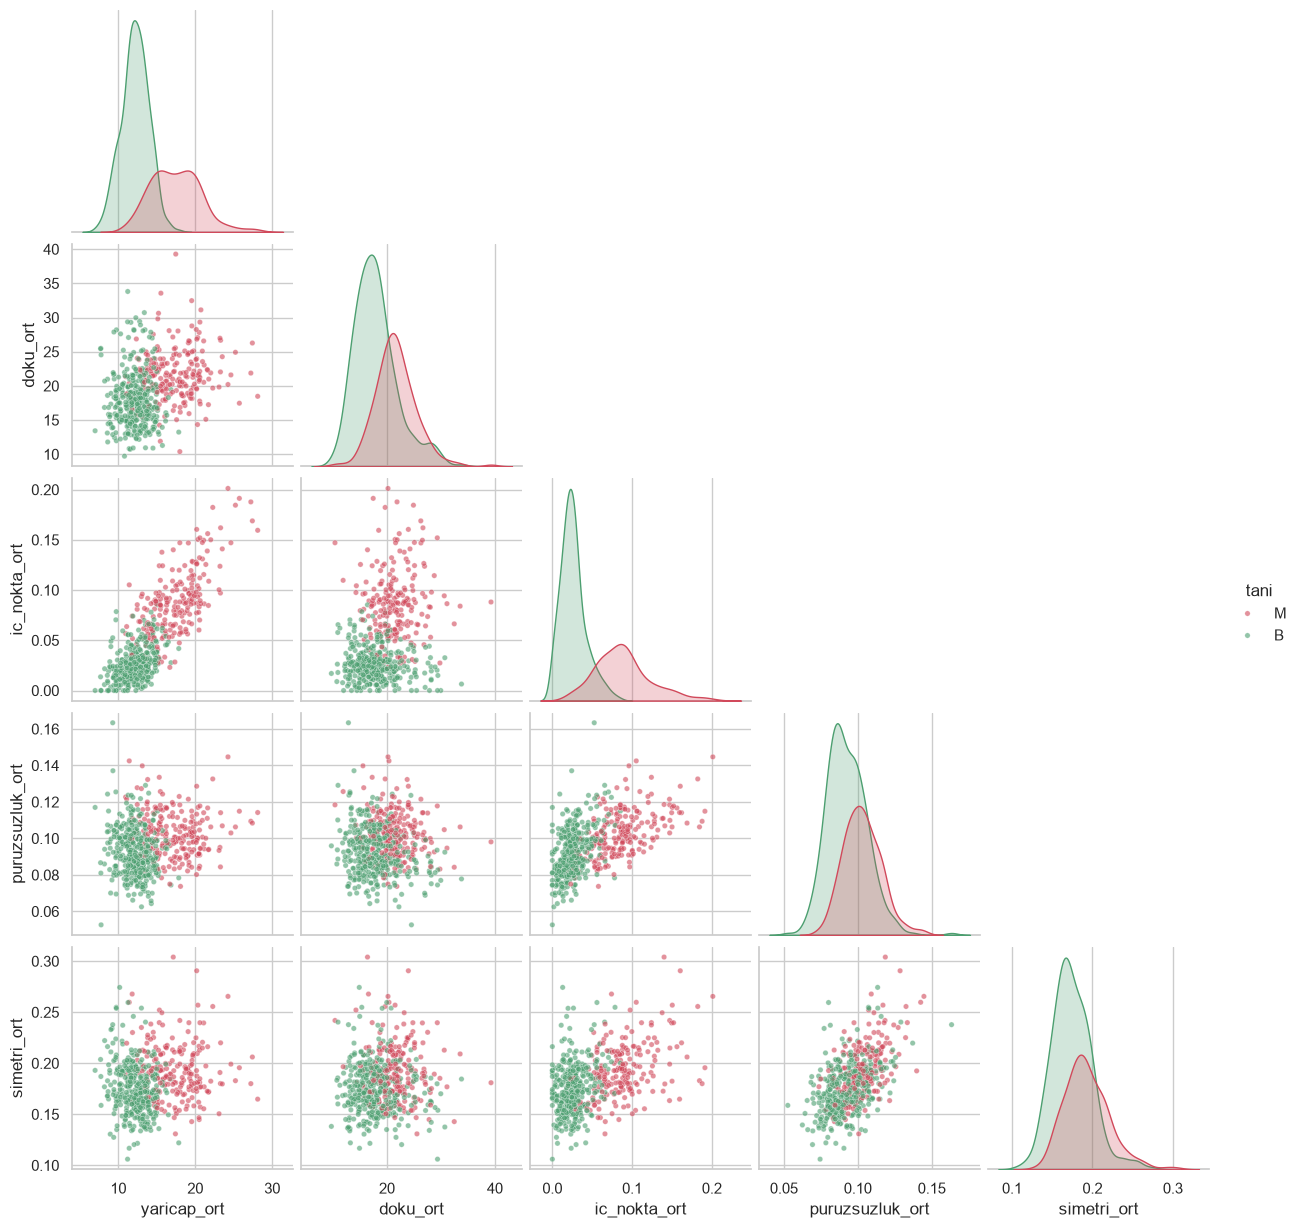

In [11]:
sns.pairplot(df, vars=["yaricap_ort", "doku_ort", "ic_nokta_ort", "puruzsuzluk_ort", "simetri_ort"],
             hue="tani", palette=RENK, diag_kind="kde", corner=True, plot_kws={"s": 15, "alpha": 0.6})
plt.show()

In [12]:
df[OZELLIKLER].describe().T

,count,mean,std,min,25%,50%,75%,max
yaricap_ort,569.0000,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100
doku_ort,569.0000,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800
cevre_ort,569.0000,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000
alan_ort,569.0000,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000
puruzsuzluk_ort,569.0000,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634
yogunluk_ort,569.0000,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454
iclik_ort,569.0000,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268
ic_nokta_ort,569.0000,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012
simetri_ort,569.0000,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040
fraktal_ort,569.0000,0.0628,0.0071,0.0500,0.0577,0.0615,0.0661,0.0974


In [13]:
def aciklayici_tablo(d):
    satirlar = {}
    for kol in d.columns:
        s = d[kol]
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        satirlar[kol] = {
            "Ortalama": s.mean(),
            "Medyan": s.median(),
            "Std. Sapma": s.std(),
            "Varyans": s.var(),
            "Değişim Kats. (%)": s.std() / s.mean() * 100,
            "Minimum": s.min(),
            "Q1": q1,
            "Q3": q3,
            "Maksimum": s.max(),
            "IQR": iqr,
            "Çarpıklık": s.skew(),
            "Basıklık": s.kurt(),
            "Aykırı (1.5·IQR)": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
        }
    return pd.DataFrame(satirlar).T

aciklayici_tablo(df[OZELLIKLER])

,Ortalama,Medyan,Std. Sapma,Varyans,Değişim Kats. (%),Minimum,Q1,Q3,Maksimum,IQR,Çarpıklık,Basıklık,Aykırı (1.5·IQR)
yaricap_ort,14.1273,13.3700,3.5240,12.4189,24.9450,6.9810,11.7000,15.7800,28.1100,4.0800,0.9424,0.8455,14.0000
doku_ort,19.2896,18.8400,4.3010,18.4989,22.2971,9.7100,16.1700,21.8000,39.2800,5.6300,0.6504,0.7583,7.0000
cevre_ort,91.9690,86.2400,24.2990,590.4405,26.4208,43.7900,75.1700,104.1000,188.5000,28.9300,0.9907,0.9722,13.0000
alan_ort,654.8891,551.1000,351.9141,123843.5543,53.7364,143.5000,420.3000,782.7000,2501.0000,362.4000,1.6457,3.6523,25.0000
puruzsuzluk_ort,0.0964,0.0959,0.0141,0.0002,14.5954,0.0526,0.0864,0.1053,0.1634,0.0189,0.4563,0.8560,6.0000
yogunluk_ort,0.1043,0.0926,0.0528,0.0028,50.6155,0.0194,0.0649,0.1304,0.3454,0.0655,1.1901,1.6501,16.0000
iclik_ort,0.0888,0.0615,0.0797,0.0064,89.7753,0.0000,0.0296,0.1307,0.4268,0.1011,1.4012,1.9986,18.0000
ic_nokta_ort,0.0489,0.0335,0.0388,0.0015,79.3204,0.0000,0.0203,0.0740,0.2012,0.0537,1.1712,1.0666,10.0000
simetri_ort,0.1812,0.1792,0.0274,0.0008,15.1325,0.1060,0.1619,0.1957,0.3040,0.0338,0.7256,1.2879,15.0000
fraktal_ort,0.0628,0.0615,0.0071,0.0000,11.2430,0.0500,0.0577,0.0661,0.0974,0.0084,1.3045,3.0059,15.0000


In [14]:
grup = []
for kol in OZELLIKLER:
    b, m = df.loc[df["tani"] == "B", kol], df.loc[df["tani"] == "M", kol]
    u, p = stats.mannwhitneyu(b, m)
    d = (m.mean() - b.mean()) / np.sqrt((b.var() + m.var()) / 2)
    grup.append({"Özellik": kol, "B ortalama": b.mean(), "B std": b.std(), "M ortalama": m.mean(), "M std": m.std(),
                 "M / B oranı": m.mean() / b.mean(), "Mann-Whitney p": p, "Cohen d": d})
grup = pd.DataFrame(grup).set_index("Özellik").sort_values("Cohen d", key=abs, ascending=False)
grup

,B ortalama,B std,M ortalama,M std,M / B oranı,Mann-Whitney p,Cohen d
Özellik,,,,,,,
ic_nokta_en_kotu,0.0744,0.0358,0.1822,0.0463,2.4480,0.0000,2.6045
cevre_en_kotu,87.0059,13.5271,141.3703,29.4571,1.6248,0.0000,2.3719
ic_nokta_ort,0.0257,0.0159,0.0880,0.0344,3.4214,0.0000,2.3251
yaricap_en_kotu,13.3798,1.9814,21.1348,4.2836,1.5796,0.0000,2.3238
cevre_ort,78.0754,11.8074,115.3654,21.8547,1.4776,0.0000,2.1230
yaricap_ort,12.1465,1.7805,17.4628,3.2040,1.4377,0.0000,2.0511
alan_en_kotu,558.8994,163.6014,1422.2863,597.9677,2.5448,0.0000,1.9696
iclik_ort,0.0461,0.0434,0.1608,0.0750,3.4907,0.0000,1.8714
alan_ort,462.7902,134.2871,978.3764,367.9380,2.1141,0.0000,1.8616


In [15]:
print(f"Sınıflar arasında anlamlı fark olan özellik sayısı (p < 0.05): {(grup['Mann-Whitney p'] < 0.05).sum()} / {len(grup)}")
print(f"Büyük etki büyüklüğüne sahip özellik sayısı (|d| > 0.8)    : {(grup['Cohen d'].abs() > 0.8).sum()} / {len(grup)}")

Sınıflar arasında anlamlı fark olan özellik sayısı (p < 0.05): 27 / 30
Büyük etki büyüklüğüne sahip özellik sayısı (|d| > 0.8)    : 20 / 30


In [16]:
X = df[OZELLIKLER]
y = (df["tani"] == "M").astype(int)
SINIFLAR = ["İyi huylu (B)", "Kötü huylu (M)"]

X_egitim, X_test, y_egitim, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

pd.DataFrame({
    "Gözlem": [len(y_egitim), len(y_test)],
    "B (0)": [(y_egitim == 0).sum(), (y_test == 0).sum()],
    "M (1)": [(y_egitim == 1).sum(), (y_test == 1).sum()],
    "M oranı (%)": [y_egitim.mean() * 100, y_test.mean() * 100],
}, index=["Eğitim", "Test"])

,Gözlem,B (0),M (1),M oranı (%)
Eğitim,455,285,170,37.3626
Test,114,72,42,36.8421


In [17]:
modeller = {
    "Lojistik Regresyon": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "Destek Vektör Makinesi (SVM)": make_pipeline(StandardScaler(), SVC(kernel="rbf")),
    "k-En Yakın Komşu (k-NN)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Rastgele Orman": RandomForestClassifier(n_estimators=300, random_state=42),
    "Karar Ağacı": DecisionTreeClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
karsilastirma = []
for ad, model in modeller.items():
    s = cross_validate(model, X_egitim, y_egitim, cv=cv,
                       scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    karsilastirma.append({"Model": ad,
                          "Doğruluk": s["test_accuracy"].mean(), "Doğruluk std": s["test_accuracy"].std(),
                          "Kesinlik": s["test_precision"].mean(), "Duyarlılık": s["test_recall"].mean(),
                          "F1": s["test_f1"].mean(), "ROC-AUC": s["test_roc_auc"].mean()})
karsilastirma = pd.DataFrame(karsilastirma).set_index("Model").sort_values("Doğruluk", ascending=False)
karsilastirma.style.highlight_max(color="lightgreen", subset=["Doğruluk", "Kesinlik", "Duyarlılık", "F1", "ROC-AUC"]) \
                   .format("{:.4f}")

,Doğruluk,Doğruluk std,Kesinlik,Duyarlılık,F1,ROC-AUC
Model,,,,,,
Lojistik Regresyon,0.9758,0.0229,0.9775,0.9588,0.9672,0.9952
Destek Vektör Makinesi (SVM),0.9714,0.0242,0.9784,0.9471,0.9601,0.9942
k-En Yakın Komşu (k-NN),0.9625,0.0397,0.9923,0.9059,0.9453,0.9875
Rastgele Orman,0.9604,0.0336,0.9580,0.9353,0.9456,0.9883
Naive Bayes,0.9405,0.0327,0.9435,0.9000,0.9180,0.9873
Karar Ağacı,0.9166,0.0389,0.8880,0.8882,0.8866,0.9109


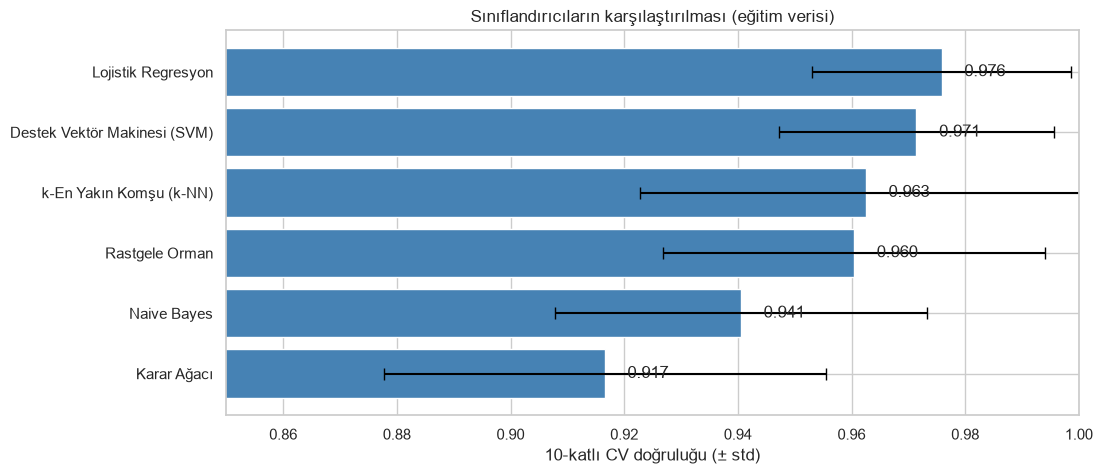

Çapraz doğrulamada en yüksek doğruluğu veren model: Lojistik Regresyon


In [18]:
fig, ax = plt.subplots(figsize=(11, 5))
k = karsilastirma.sort_values("Doğruluk")
ax.barh(k.index, k["Doğruluk"], xerr=k["Doğruluk std"], color="steelblue", capsize=4)
for i, v in enumerate(k["Doğruluk"]):
    ax.text(v + 0.004, i, f"{v:.3f}", va="center")
ax.set_xlim(0.85, 1.0)
ax.set_xlabel("10-katlı CV doğruluğu (± std)")
ax.set_title("Sınıflandırıcıların karşılaştırılması (eğitim verisi)")
plt.show()

EN_IYI = karsilastirma.index[0]
print(f"Çapraz doğrulamada en yüksek doğruluğu veren model: {EN_IYI}")

In [19]:
model = modeller[EN_IYI]
model.fit(X_egitim, y_egitim)

y_tahmin = model.predict(X_test)
y_olasilik = model.predict_proba(X_test)[:, 1]

sonuc = X_test[["yaricap_ort", "doku_ort", "ic_nokta_ort"]].copy()
sonuc["Gerçek"] = y_test.map({0: "B", 1: "M"})
sonuc["Tahmin"] = pd.Series(y_tahmin, index=X_test.index).map({0: "B", 1: "M"})
sonuc["P(M)"] = y_olasilik
sonuc["Doğru mu?"] = np.where(sonuc["Gerçek"] == sonuc["Tahmin"], "✓", "✗")
print("Test verisi tahminlerinden örnekler:")
sonuc.head(12)

Test verisi tahminlerinden örnekler:


,yaricap_ort,doku_ort,ic_nokta_ort,Gerçek,Tahmin,P(M),Doğru mu?
120,11.4100,10.8200,0.0262,B,B,0.0004,✓
250,20.9400,23.5600,0.1310,M,M,1.0000,✓
375,16.1700,16.0700,0.0540,B,B,0.0426,✓
99,14.4200,19.7700,0.0584,M,M,0.5762,✓
455,13.3800,30.7200,0.0326,B,M,0.5092,✗
318,9.0420,18.9000,0.0491,B,B,0.0006,✓
39,13.4800,20.8200,0.0544,M,M,0.7615,✓
371,15.1900,13.2100,0.0266,B,B,0.0010,✓
98,11.6000,12.8400,0.0335,B,B,0.0006,✓
502,12.5400,16.3200,0.0328,B,B,0.0108,✓


In [20]:
print(f"Eğitim doğruluğu : {accuracy_score(y_egitim, model.predict(X_egitim)):.4f}")
print(f"Test doğruluğu   : {accuracy_score(y_test, y_tahmin):.4f}")
print(f"CV doğruluğu     : {karsilastirma.loc[EN_IYI, 'Doğruluk']:.4f} ± {karsilastirma.loc[EN_IYI, 'Doğruluk std']:.4f}")

Eğitim doğruluğu : 0.9868
Test doğruluğu   : 0.9649
CV doğruluğu     : 0.9758 ± 0.0229


In [21]:
katsayi = pd.Series(model[-1].coef_[0], index=OZELLIKLER)
katsayi_df = pd.DataFrame({"Katsayı (β, standart ölçek)": katsayi, "Odds oranı (e^β)": np.exp(katsayi)}) \
               .sort_values("Katsayı (β, standart ölçek)", key=abs, ascending=False)
print(f"Sabit terim (β0): {model[-1].intercept_[0]:.4f}")
katsayi_df.head(10)

Sabit terim (β0): -0.2430


,"Katsayı (β, standart ölçek)",Odds oranı (e^β)
doku_en_kotu,1.4341,4.1958
yaricap_se,1.2333,3.4326
simetri_en_kotu,1.0613,2.8900
ic_nokta_ort,0.9528,2.5930
iclik_en_kotu,0.9114,2.4878
alan_se,0.9090,2.4819
yogunluk_se,-0.9069,0.4038
alan_en_kotu,0.9005,2.4608
yaricap_en_kotu,0.8970,2.4522
iclik_ort,0.7823,2.1865


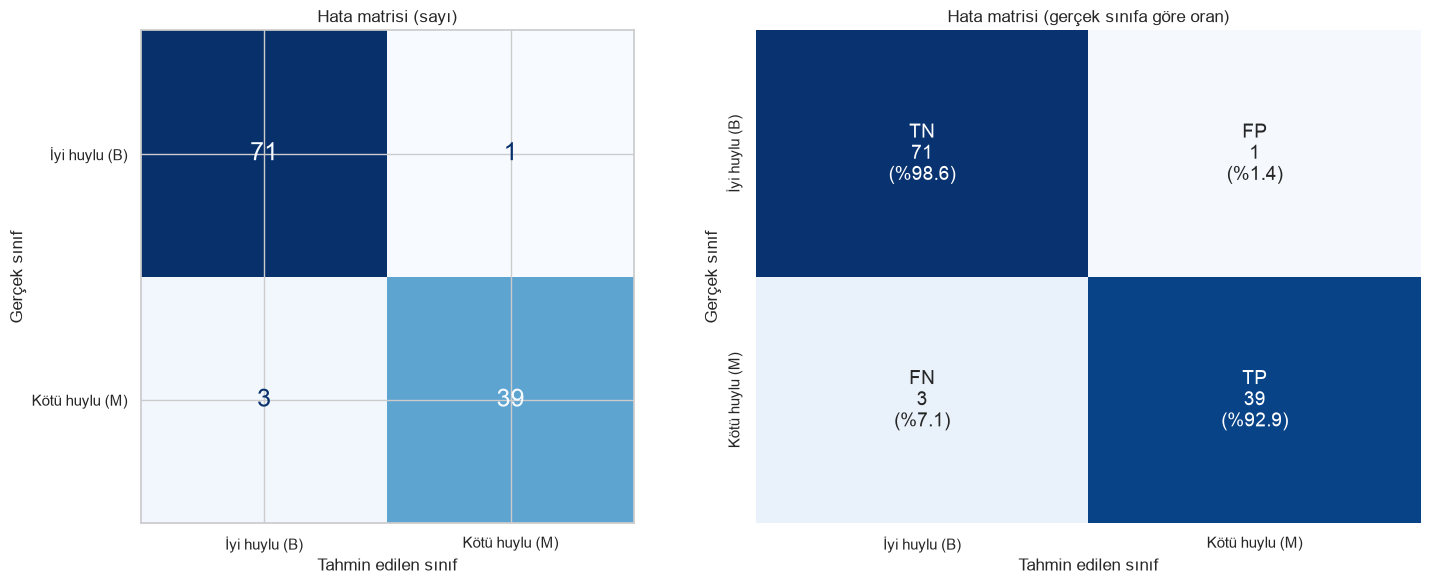

In [22]:
cm = confusion_matrix(y_test, y_tahmin)
TN, FP, FN, TP = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ConfusionMatrixDisplay(cm, display_labels=SINIFLAR).plot(cmap="Blues", ax=axes[0], colorbar=False,
                                                         text_kw={"fontsize": 18})
axes[0].set_title("Hata matrisi (sayı)")
axes[0].set_xlabel("Tahmin edilen sınıf")
axes[0].set_ylabel("Gerçek sınıf")

cm_oran = confusion_matrix(y_test, y_tahmin, normalize="true")
etiket = np.array([[f"TN\n{TN}\n(%{cm_oran[0, 0] * 100:.1f})", f"FP\n{FP}\n(%{cm_oran[0, 1] * 100:.1f})"],
                   [f"FN\n{FN}\n(%{cm_oran[1, 0] * 100:.1f})", f"TP\n{TP}\n(%{cm_oran[1, 1] * 100:.1f})"]])
sns.heatmap(cm_oran, annot=etiket, fmt="", cmap="Blues", cbar=False, ax=axes[1], annot_kws={"fontsize": 14},
            xticklabels=SINIFLAR, yticklabels=SINIFLAR, vmin=0, vmax=1)
axes[1].set_title("Hata matrisi (gerçek sınıfa göre oran)")
axes[1].set_xlabel("Tahmin edilen sınıf")
axes[1].set_ylabel("Gerçek sınıf")
plt.tight_layout()
plt.show()

In [23]:
n = cm.sum()
pd.DataFrame({
    "Değer": [TP, TN, FP, FN, TP + TN, FP + FN],
    "Açıklama": [
        "Kötü huylu tümör doğru olarak 'kötü huylu' bulundu",
        "İyi huylu tümör doğru olarak 'iyi huylu' bulundu",
        "İyi huylu tümör yanlışlıkla 'kötü huylu' dendi (gereksiz alarm)",
        "Kötü huylu tümör yanlışlıkla 'iyi huylu' dendi (KAÇIRILAN KANSER)",
        f"Toplam doğru sınıflandırma (%{(TP + TN) / n * 100:.2f})",
        f"Toplam hatalı sınıflandırma (%{(FP + FN) / n * 100:.2f})",
    ],
}, index=["TP (Doğru Pozitif)", "TN (Doğru Negatif)", "FP (Yanlış Pozitif – Tip I)",
          "FN (Yanlış Negatif – Tip II)", "Doğru", "Hatalı"])

,Değer,Açıklama
TP (Doğru Pozitif),39,Kötü huylu tümör doğru olarak 'kötü huylu' bul...
TN (Doğru Negatif),71,İyi huylu tümör doğru olarak 'iyi huylu' bulundu
FP (Yanlış Pozitif – Tip I),1,İyi huylu tümör yanlışlıkla 'kötü huylu' dendi...
FN (Yanlış Negatif – Tip II),3,Kötü huylu tümör yanlışlıkla 'iyi huylu' dendi...
Doğru,110,Toplam doğru sınıflandırma (%96.49)
Hatalı,4,Toplam hatalı sınıflandırma (%3.51)


In [24]:
olcutler = pd.DataFrame({
    "Formül": ["(TP+TN)/n", "TP/(TP+FN)", "TN/(TN+FP)", "TP/(TP+FP)", "TN/(TN+FN)",
               "FP/(FP+TN)", "FN/(FN+TP)", "(FP+FN)/n"],
    "Değer": [(TP + TN) / n, TP / (TP + FN), TN / (TN + FP), TP / (TP + FP), TN / (TN + FN),
              FP / (FP + TN), FN / (FN + TP), (FP + FN) / n],
}, index=["Doğruluk (Accuracy)", "Duyarlılık (Sensitivity / Recall / TPR)", "Özgüllük (Specificity / TNR)",
          "Kesinlik (Precision / PPV)", "Negatif Kestirim Değeri (NPV)", "Yanlış Pozitif Oranı (FPR)",
          "Yanlış Negatif Oranı (FNR)", "Hata Oranı"])
olcutler

,Formül,Değer
Doğruluk (Accuracy),(TP+TN)/n,0.9649
Duyarlılık (Sensitivity / Recall / TPR),TP/(TP+FN),0.9286
Özgüllük (Specificity / TNR),TN/(TN+FP),0.9861
Kesinlik (Precision / PPV),TP/(TP+FP),0.9750
Negatif Kestirim Değeri (NPV),TN/(TN+FN),0.9595
Yanlış Pozitif Oranı (FPR),FP/(FP+TN),0.0139
Yanlış Negatif Oranı (FNR),FN/(FN+TP),0.0714
Hata Oranı,(FP+FN)/n,0.0351


In [25]:
hatali = sonuc.copy()
hatali["P(M)"] = y_olasilik
hatali = hatali[hatali["Doğru mu?"] == "✗"].sort_values("P(M)")
hatali["Hata türü"] = np.where(hatali["Gerçek"] == "M", "FN (kaçırılan M)", "FP (yanlış alarm)")
hatali

,yaricap_ort,doku_ort,ic_nokta_ort,Gerçek,Tahmin,P(M),Doğru mu?,Hata türü
73,13.8000,15.7900,0.0507,M,B,0.0614,✗,FN (kaçırılan M)
190,14.2200,23.1200,0.0662,M,B,0.3145,✗,FN (kaçırılan M)
205,15.1200,16.6800,0.0408,M,B,0.4916,✗,FN (kaçırılan M)
455,13.3800,30.7200,0.0326,B,M,0.5092,✗,FP (yanlış alarm)


In [26]:
print("SINIFLANDIRMA RAPORU — Lojistik Regresyon (test verisi, eşik = 0.5)")
print("=" * 66)
print(classification_report(y_test, y_tahmin, target_names=SINIFLAR, digits=4))

SINIFLANDIRMA RAPORU — Lojistik Regresyon (test verisi, eşik = 0.5)
                precision    recall  f1-score   support

 İyi huylu (B)     0.9595    0.9861    0.9726        72
Kötü huylu (M)     0.9750    0.9286    0.9512        42

      accuracy                         0.9649       114
     macro avg     0.9672    0.9573    0.9619       114
  weighted avg     0.9652    0.9649    0.9647       114



In [27]:
rapor_df = pd.DataFrame(classification_report(y_test, y_tahmin, target_names=SINIFLAR, output_dict=True)).T
rapor_df.loc["accuracy", ["precision", "recall", "support"]] = [np.nan, np.nan, len(y_test)]
rapor_df.columns = ["Kesinlik (Precision)", "Duyarlılık (Recall)", "F1-Skoru", "Destek (n)"]
rapor_df.index = ["İyi huylu (B)", "Kötü huylu (M)", "Doğruluk", "Makro ortalama", "Ağırlıklı ortalama"]
rapor_df

,Kesinlik (Precision),Duyarlılık (Recall),F1-Skoru,Destek (n)
İyi huylu (B),0.9595,0.9861,0.9726,72.0000
Kötü huylu (M),0.9750,0.9286,0.9512,42.0000
Doğruluk,NaN,NaN,0.9649,114.0000
Makro ortalama,0.9672,0.9573,0.9619,114.0000
Ağırlıklı ortalama,0.9652,0.9649,0.9647,114.0000


In [28]:
ek = pd.Series({
    "Doğruluk (Accuracy)": accuracy_score(y_test, y_tahmin),
    "Dengeli doğruluk (Balanced accuracy)": balanced_accuracy_score(y_test, y_tahmin),
    "Kesinlik (M)": precision_score(y_test, y_tahmin),
    "Duyarlılık (M)": recall_score(y_test, y_tahmin),
    "F1-skoru (M)": f1_score(y_test, y_tahmin),
    "ROC-AUC": roc_auc_score(y_test, y_olasilik),
    "Ortalama kesinlik (PR-AUC)": average_precision_score(y_test, y_olasilik),
    "Matthews korelasyon katsayısı (MCC)": matthews_corrcoef(y_test, y_tahmin),
    "Cohen Kappa": cohen_kappa_score(y_test, y_tahmin),
    "Log-loss (↓)": log_loss(y_test, y_olasilik),
}).to_frame("Değer")
ek

,Değer
Doğruluk (Accuracy),0.9649
Dengeli doğruluk (Balanced accuracy),0.9573
Kesinlik (M),0.9750
Duyarlılık (M),0.9286
F1-skoru (M),0.9512
ROC-AUC,0.9960
Ortalama kesinlik (PR-AUC),0.9943
Matthews korelasyon katsayısı (MCC),0.9245
Cohen Kappa,0.9238
Log-loss (↓),0.0773


In [29]:
rng = np.random.default_rng(42)
yt, yp, yo = y_test.values, y_tahmin, y_olasilik
bs = {"Doğruluk": [], "Kesinlik (M)": [], "Duyarlılık (M)": [], "F1 (M)": [], "ROC-AUC": []}
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].min() == yt[i].max():
        continue
    bs["Doğruluk"].append(accuracy_score(yt[i], yp[i]))
    bs["Kesinlik (M)"].append(precision_score(yt[i], yp[i], zero_division=0))
    bs["Duyarlılık (M)"].append(recall_score(yt[i], yp[i]))
    bs["F1 (M)"].append(f1_score(yt[i], yp[i]))
    bs["ROC-AUC"].append(roc_auc_score(yt[i], yo[i]))
pd.DataFrame({k: {"Ortalama": np.mean(v), "%95 GA Alt": np.percentile(v, 2.5), "%95 GA Üst": np.percentile(v, 97.5)}
              for k, v in bs.items()}).T

,Ortalama,%95 GA Alt,%95 GA Üst
Doğruluk,0.9647,0.9298,0.9912
Kesinlik (M),0.9749,0.9118,1.0000
Duyarlılık (M),0.9280,0.8409,1.0000
F1 (M),0.9502,0.8947,0.9895
ROC-AUC,0.9961,0.9863,1.0000


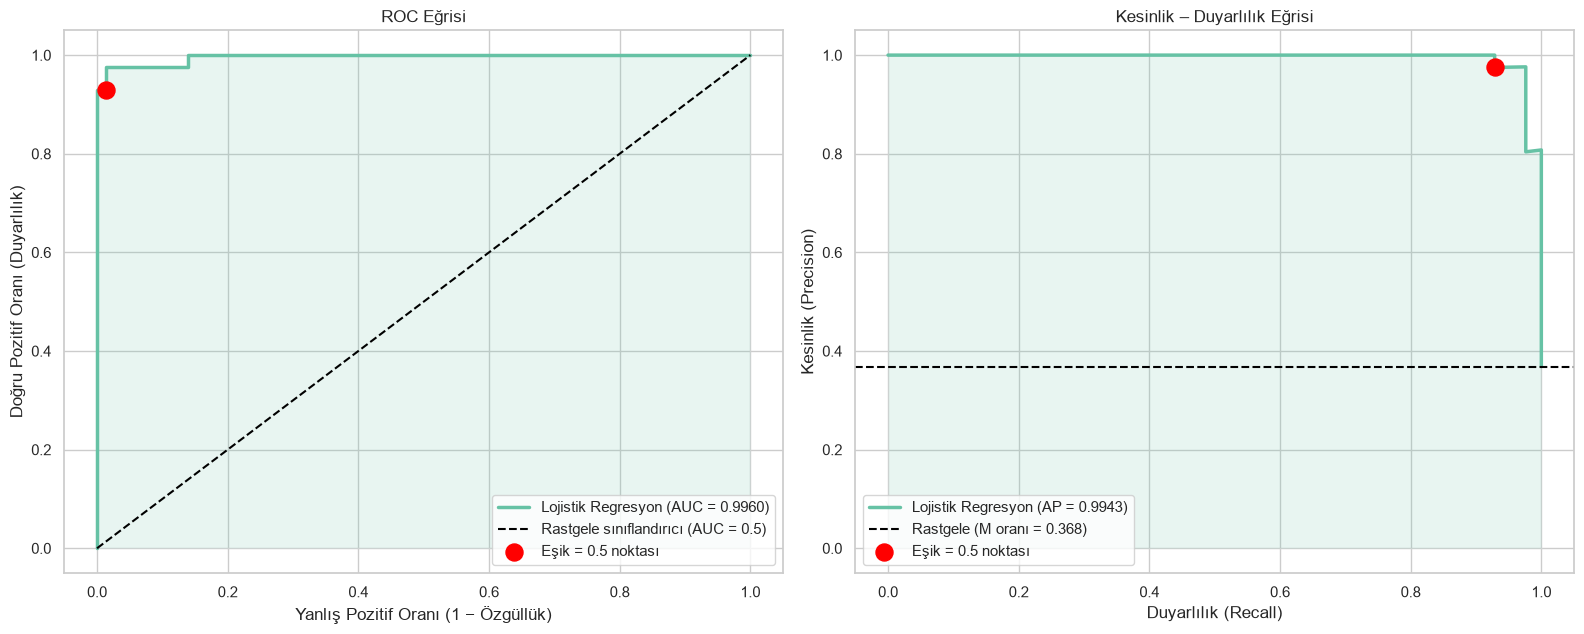

In [30]:
fpr, tpr, roc_esik = roc_curve(y_test, y_olasilik)
kes, duy, pr_esik = precision_recall_curve(y_test, y_olasilik)
auc = roc_auc_score(y_test, y_olasilik)
ap = average_precision_score(y_test, y_olasilik)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
axes[0].plot(fpr, tpr, linewidth=2.5, label=f"Lojistik Regresyon (AUC = {auc:.4f})")
axes[0].fill_between(fpr, tpr, alpha=0.15)
axes[0].plot([0, 1], [0, 1], "k--", label="Rastgele sınıflandırıcı (AUC = 0.5)")
axes[0].scatter(FP / (FP + TN), TP / (TP + FN), s=150, c="red", zorder=5, label="Eşik = 0.5 noktası")
axes[0].set_xlabel("Yanlış Pozitif Oranı (1 − Özgüllük)")
axes[0].set_ylabel("Doğru Pozitif Oranı (Duyarlılık)")
axes[0].set_title("ROC Eğrisi")
axes[0].legend(loc="lower right")

axes[1].plot(duy, kes, linewidth=2.5, label=f"Lojistik Regresyon (AP = {ap:.4f})")
axes[1].fill_between(duy, kes, alpha=0.15)
axes[1].axhline(y_test.mean(), color="black", linestyle="--", label=f"Rastgele (M oranı = {y_test.mean():.3f})")
axes[1].scatter(TP / (TP + FN), TP / (TP + FP), s=150, c="red", zorder=5, label="Eşik = 0.5 noktası")
axes[1].set_xlabel("Duyarlılık (Recall)")
axes[1].set_ylabel("Kesinlik (Precision)")
axes[1].set_title("Kesinlik – Duyarlılık Eğrisi")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()

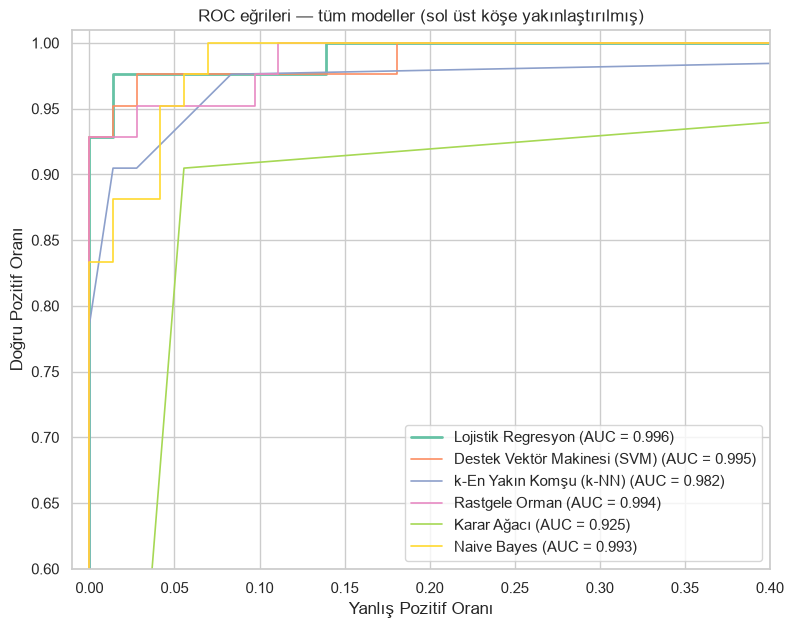

In [31]:
fig, ax = plt.subplots(figsize=(9, 7))
for ad, m in modeller.items():
    m.fit(X_egitim, y_egitim)
    skor = m.predict_proba(X_test)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(X_test)
    f, t, _ = roc_curve(y_test, skor)
    ax.plot(f, t, linewidth=2 if ad == EN_IYI else 1.2, label=f"{ad} (AUC = {roc_auc_score(y_test, skor):.3f})")
ax.plot([0, 1], [0, 1], "k--")
ax.set_xlim(-0.01, 0.4)
ax.set_ylim(0.6, 1.01)
ax.set_xlabel("Yanlış Pozitif Oranı")
ax.set_ylabel("Doğru Pozitif Oranı")
ax.set_title("ROC eğrileri — tüm modeller (sol üst köşe yakınlaştırılmış)")
ax.legend(loc="lower right")
plt.show()

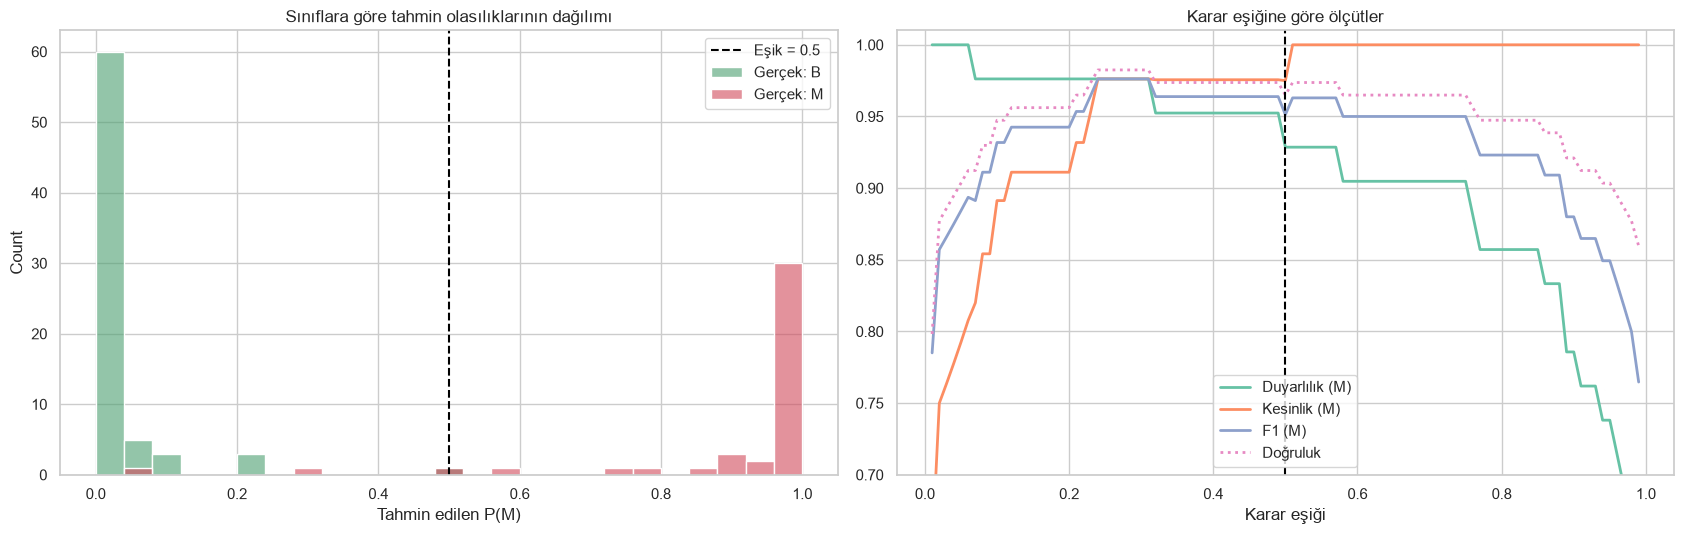

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
for deger, ad, renk in [(0, "Gerçek: B", RENK["B"]), (1, "Gerçek: M", RENK["M"])]:
    sns.histplot(y_olasilik[y_test == deger], bins=25, binrange=(0, 1), color=renk, alpha=0.6, label=ad, ax=axes[0])
axes[0].axvline(0.5, color="black", linestyle="--", label="Eşik = 0.5")
axes[0].set_xlabel("Tahmin edilen P(M)")
axes[0].set_title("Sınıflara göre tahmin olasılıklarının dağılımı")
axes[0].legend()

esikler = np.linspace(0.01, 0.99, 99)
axes[1].plot(esikler, [recall_score(y_test, y_olasilik >= e) for e in esikler], label="Duyarlılık (M)", linewidth=2)
axes[1].plot(esikler, [precision_score(y_test, y_olasilik >= e, zero_division=1) for e in esikler], label="Kesinlik (M)", linewidth=2)
axes[1].plot(esikler, [f1_score(y_test, y_olasilik >= e) for e in esikler], label="F1 (M)", linewidth=2)
axes[1].plot(esikler, [accuracy_score(y_test, y_olasilik >= e) for e in esikler], label="Doğruluk", linewidth=2, linestyle=":")
axes[1].axvline(0.5, color="black", linestyle="--")
axes[1].set_xlabel("Karar eşiği")
axes[1].set_ylim(0.7, 1.01)
axes[1].set_title("Karar eşiğine göre ölçütler")
axes[1].legend(loc="lower center")
plt.tight_layout()
plt.show()

In [33]:
esik_tablo = []
for e in [0.10, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.70]:
    tn, fp, fn, tp = confusion_matrix(y_test, (y_olasilik >= e).astype(int)).ravel()
    esik_tablo.append({"Eşik": e, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                       "Duyarlılık": tp / (tp + fn), "Özgüllük": tn / (tn + fp),
                       "Kesinlik": tp / (tp + fp), "Doğruluk": (tp + tn) / len(y_test)})
print("Karar eşiğinin hata matrisine etkisi (açıklama amaçlı; pratikte eşik ayrı bir doğrulama kümesinde seçilmelidir)")
pd.DataFrame(esik_tablo).set_index("Eşik")

Karar eşiğinin hata matrisine etkisi (açıklama amaçlı; pratikte eşik ayrı bir doğrulama kümesinde seçilmelidir)


,TN,FP,FN,TP,Duyarlılık,Özgüllük,Kesinlik,Doğruluk
Eşik,,,,,,,,
0.1000,67,5,1,41,0.9762,0.9306,0.8913,0.9474
0.2000,68,4,1,41,0.9762,0.9444,0.9111,0.9561
0.2500,71,1,1,41,0.9762,0.9861,0.9762,0.9825
0.3000,71,1,1,41,0.9762,0.9861,0.9762,0.9825
0.4000,71,1,2,40,0.9524,0.9861,0.9756,0.9737
0.5000,71,1,3,39,0.9286,0.9861,0.9750,0.9649
0.6000,72,0,4,38,0.9048,1.0000,1.0000,0.9649
0.7000,72,0,4,38,0.9048,1.0000,1.0000,0.9649


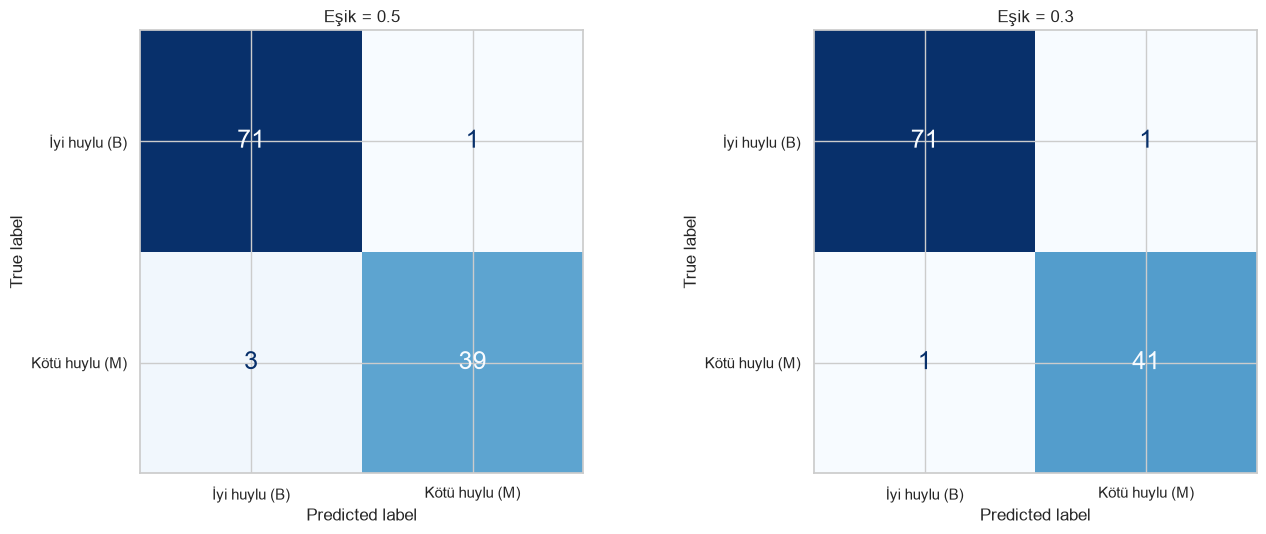

In [34]:
ESIK_YENI = 0.30
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, e in zip(axes, [0.5, ESIK_YENI]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, (y_olasilik >= e).astype(int)), display_labels=SINIFLAR) \
        .plot(cmap="Blues", ax=ax, colorbar=False, text_kw={"fontsize": 18})
    ax.set_title(f"Eşik = {e}")
plt.tight_layout()
plt.show()

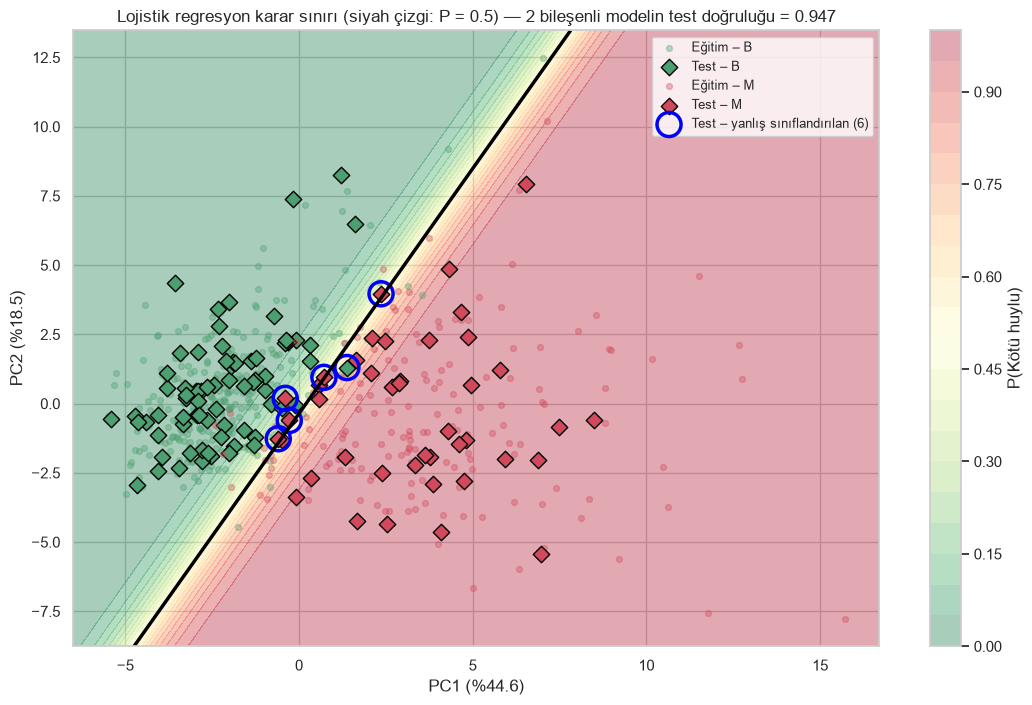

In [35]:
pca_model = make_pipeline(StandardScaler(), PCA(n_components=2), LogisticRegression(max_iter=5000))
pca_model.fit(X_egitim, y_egitim)
P_egitim = pca_model[:2].transform(X_egitim)
P_test = pca_model[:2].transform(X_test)
ev = pca_model[1].explained_variance_ratio_

pay = 1.0
xx, yy = np.meshgrid(np.linspace(min(P_egitim[:, 0].min(), P_test[:, 0].min()) - pay,
                                 max(P_egitim[:, 0].max(), P_test[:, 0].max()) + pay, 400),
                     np.linspace(min(P_egitim[:, 1].min(), P_test[:, 1].min()) - pay,
                                 max(P_egitim[:, 1].max(), P_test[:, 1].max()) + pay, 400))
olasilik_izgara = pca_model[-1].predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1].reshape(xx.shape)
pca_test_tahmin = pca_model.predict(X_test)

fig, ax = plt.subplots(figsize=(13, 8))
kontur = ax.contourf(xx, yy, olasilik_izgara, levels=20, cmap="RdYlGn_r", alpha=0.35)
plt.colorbar(kontur, label="P(Kötü huylu)")
ax.contour(xx, yy, olasilik_izgara, levels=[0.5], colors="black", linewidths=2.5)
for deger, ad in [(0, "B"), (1, "M")]:
    m = y_egitim.values == deger
    ax.scatter(P_egitim[m, 0], P_egitim[m, 1], c=RENK[ad], s=18, alpha=0.35, label=f"Eğitim – {ad}")
    m = y_test.values == deger
    ax.scatter(P_test[m, 0], P_test[m, 1], c=RENK[ad], s=70, edgecolor="black", marker="D", label=f"Test – {ad}")
yanlis = pca_test_tahmin != y_test.values
ax.scatter(P_test[yanlis, 0], P_test[yanlis, 1], s=300, facecolor="none", edgecolor="blue", linewidth=2.5,
           label=f"Test – yanlış sınıflandırılan ({yanlis.sum()})")
ax.set_xlabel(f"PC1 (%{ev[0] * 100:.1f})")
ax.set_ylabel(f"PC2 (%{ev[1] * 100:.1f})")
ax.set_title(f"Lojistik regresyon karar sınırı (siyah çizgi: P = 0.5) — 2 bileşenli modelin test doğruluğu = "
             f"{accuracy_score(y_test, pca_test_tahmin):.3f}")
ax.legend(loc="upper right", fontsize=9)
plt.show()

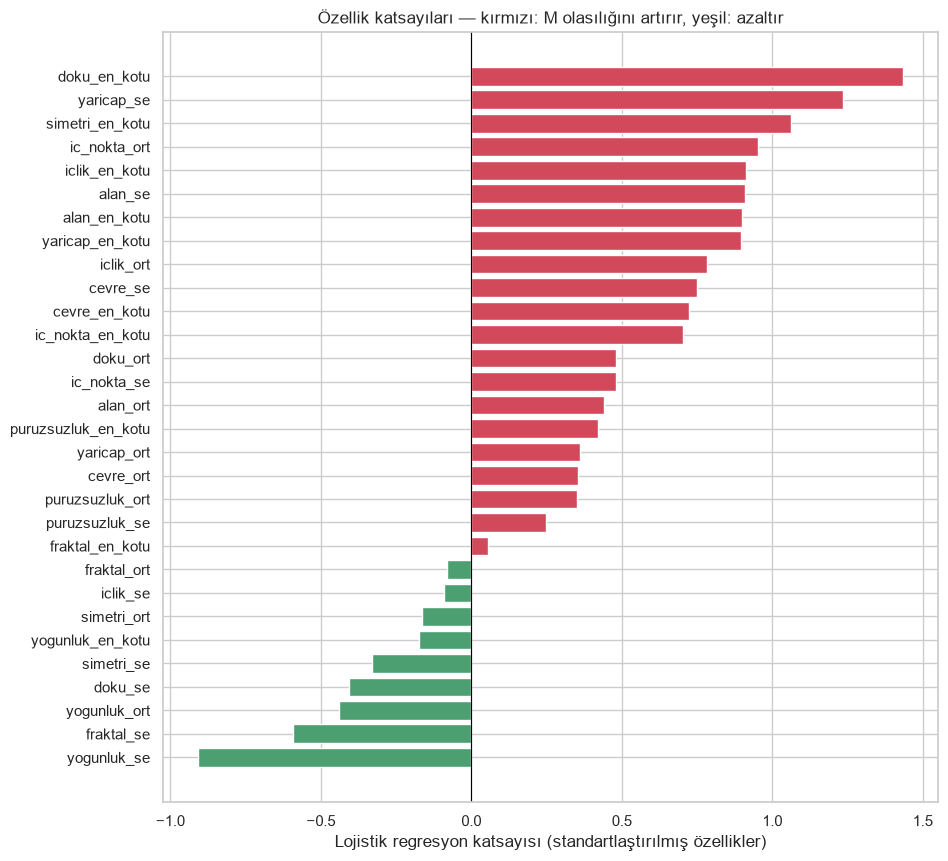

In [36]:
k = katsayi.sort_values()
fig, ax = plt.subplots(figsize=(10, 10))
ax.barh(k.index, k.values, color=np.where(k > 0, RENK["M"], RENK["B"]))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Lojistik regresyon katsayısı (standartlaştırılmış özellikler)")
ax.set_title("Özellik katsayıları — kırmızı: M olasılığını artırır, yeşil: azaltır")
plt.show()

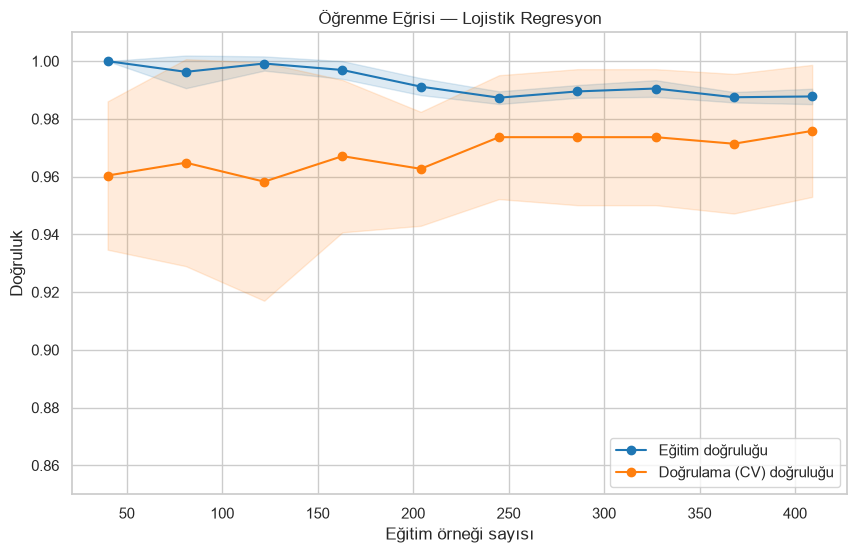

In [37]:
boyut, egitim_skor, dogrulama_skor = learning_curve(
    modeller[EN_IYI], X_egitim, y_egitim, cv=cv, train_sizes=np.linspace(0.1, 1.0, 10), scoring="accuracy")

fig, ax = plt.subplots(figsize=(10, 6))
for skor, ad, renk in [(egitim_skor, "Eğitim doğruluğu", "tab:blue"), (dogrulama_skor, "Doğrulama (CV) doğruluğu", "tab:orange")]:
    ax.plot(boyut, skor.mean(axis=1), "o-", color=renk, label=ad)
    ax.fill_between(boyut, skor.mean(axis=1) - skor.std(axis=1), skor.mean(axis=1) + skor.std(axis=1), color=renk, alpha=0.15)
ax.set_xlabel("Eğitim örneği sayısı")
ax.set_ylabel("Doğruluk")
ax.set_ylim(0.85, 1.01)
ax.set_title("Öğrenme Eğrisi — Lojistik Regresyon")
ax.legend(loc="lower right")
plt.show()

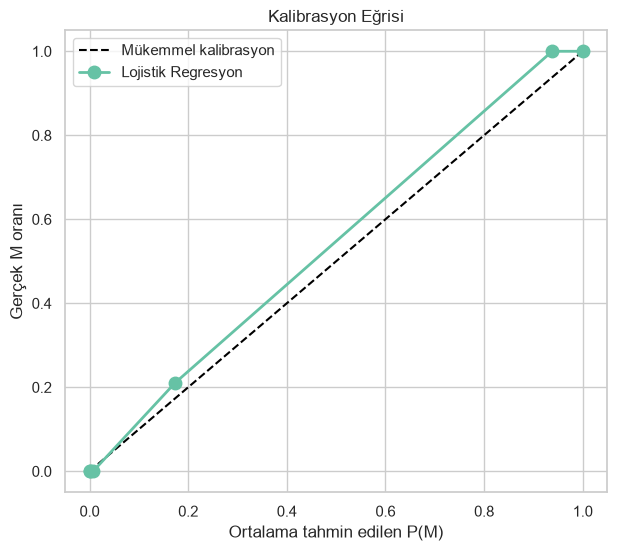

In [38]:
from sklearn.calibration import calibration_curve
gercek_oran, tahmin_oran = calibration_curve(y_test, y_olasilik, n_bins=6, strategy="quantile")
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "k--", label="Mükemmel kalibrasyon")
ax.plot(tahmin_oran, gercek_oran, "o-", linewidth=2, markersize=9, label="Lojistik Regresyon")
ax.set_xlabel("Ortalama tahmin edilen P(M)")
ax.set_ylabel("Gerçek M oranı")
ax.set_title("Kalibrasyon Eğrisi")
ax.legend()
plt.show()